# Math 

In [30]:
import numpy as np

In [2]:
# Dataset: [Maths, Science]
X = np.array([[2,2],[3,3],[4,5],[5,4],[6,6]], dtype=float)
X

array([[2., 2.],
       [3., 3.],
       [4., 5.],
       [5., 4.],
       [6., 6.]])

In [3]:
# Step 1: Subtract mean
mean = np.mean(X, axis=0)
X_centered = X - mean

In [7]:
X_centered

array([[-2., -2.],
       [-1., -1.],
       [ 0.,  1.],
       [ 1.,  0.],
       [ 2.,  2.]])

In [6]:
# Step 2: Covariance matrix
cov = np.cov(X_centered, rowvar=False)
print("Covariance Matrix:\n", cov)

Covariance Matrix:
 [[2.5  2.25]
 [2.25 2.5 ]]


In [8]:
# Step 3: Eigenvalues and Eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov)

In [9]:
eigenvalues

array([4.75, 0.25])

In [12]:
# Step 4: Sort (largest eigenvalue first)
idx =np.argsort(eigenvalues)[::-1] # [::-1] replaces argsort
eigenvalues  = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

In [13]:
# Step 5: Explained variance
total = np.sum(eigenvalues)
for i, ev in enumerate(eigenvalues):
    print(f"PC{i+1} explains {ev/total*100:.1f}% variance")

PC1 explains 95.0% variance
PC2 explains 5.0% variance


In [14]:
# Step 6: Project onto PC1
W = eigenvectors[:, :1]           # take PC1 only
X_pca = X_centered @ W
print("Projected 1D data:", X_pca.flatten())

Projected 1D data: [-2.82842712 -1.41421356  0.70710678  0.70710678  2.82842712]


# PCA with Scikit-Learn (Iris Dataset)

In [34]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
X.shape

(150, 4)

In [3]:
# Always scale for pca
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# Apply pca
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [5]:
evr = pca.explained_variance_ratio_
print(f"PC1: {evr[0]*100:.1f}%,  PC2: {evr[1]*100:.1f}%")
print(f"Total variance kept: {sum(evr)*100:.1f}%")

PC1: 73.0%,  PC2: 22.9%
Total variance kept: 95.8%


In [6]:
import seaborn as sns

In [7]:
X_pca[:,1].shape

(150,)

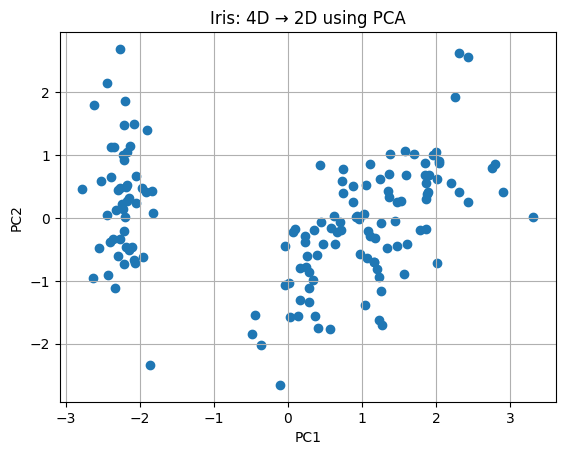

In [32]:
plt.scatter(X_pca[:,0],X_pca[:,1],)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title('Iris: 4D → 2D using PCA')
plt.grid(True)
plt.show()

In [33]:
# # Visualize
# colors = ['red','blue','green']
# for i, (color, label) in enumerate(zip(colors, iris.target_names)):
#     mask = y == i
#     plt.scatter(X_pca[mask,0], X_pca[mask,1], c=color, label=label, alpha=0.7)

# plt.xlabel(f'PC1 ({evr[0]*100:.1f}%)')
# plt.ylabel(f'PC2 ({evr[1]*100:.1f}%)')
# plt.title('Iris: 4D → 2D using PCA')
# plt.legend(); plt.grid(True); plt.show()

In [8]:
pca.explained_variance_ratio_

array([0.72962445, 0.22850762])

# Choosing the Right Number of Dimensions

In [12]:
pca_full = PCA()
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)* 100
print(pca_full.explained_variance_ratio_)
cum_var

[0.72962445 0.22850762 0.03668922 0.00517871]


array([ 72.96244541,  95.8132072 ,  99.48212909, 100.        ])

In [16]:
for i in range(1,len(cum_var)+1):
    print(i)

1
2
3
4


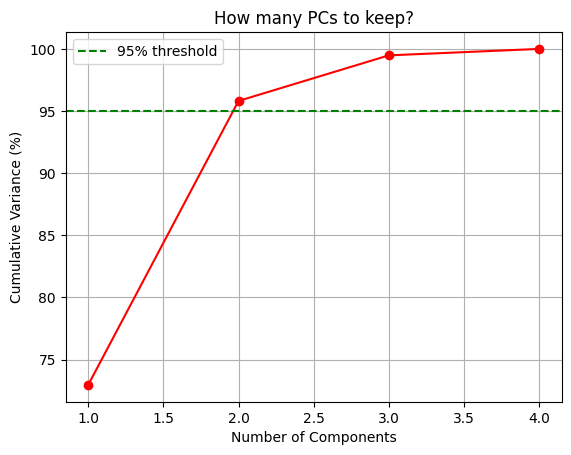

In [19]:
plt.plot(range(1,len(cum_var)+1),cum_var,"o-",color="red")
plt.axhline(95,linestyle='--', color='green', label='95% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance (%)')
plt.title('How many PCs to keep?')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
cum_var >= 95

array([False,  True,  True,  True])

In [28]:
np.argmax(cum_var >= 95) # Returns the indices of the maximum values along an axis.

np.int64(1)

In [29]:
# # Find minimum components for 95% variance
n = np.argmax(cum_var >= 95) + 1 # +1 because it return indices
print(f"Need {n} components for 95% variance")

Need 2 components for 95% variance


In [32]:
# choose right d for MNIST dataset

In [33]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', as_frame=False)
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

In [35]:
pca_full =PCA()
pca_full.fit(X_train)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [37]:
cum_sum = np.cumsum(pca_full.explained_variance_ratio_)
d = np.argmax(cum_sum>=0.95)+1
d

np.int64(154)

You could then set n_components=d and run PCA again. 

but, There is an another method we can you can set n_components to be a float between 0.0 and 1.0,
indicating the ratio of variance you wish to preserve. see below code

In [39]:
pca =PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)
pca.n_components_

np.int64(154)

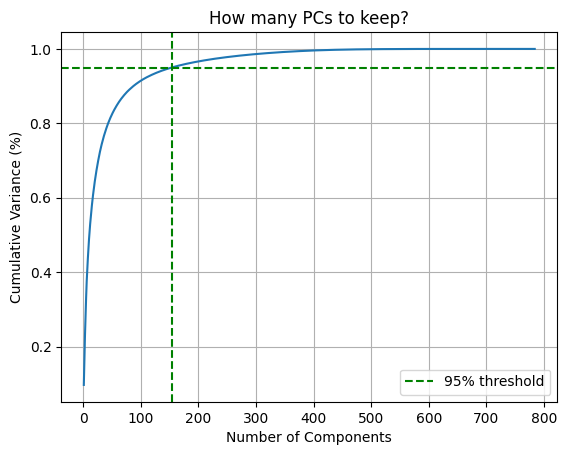

In [40]:
plt.plot(range(1,len(cum_sum)+1),cum_sum)
plt.axhline(0.95,linestyle='--', color='green', label='95% threshold')
plt.axvline(d,linestyle='--', color='green')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance (%)')
plt.title('How many PCs to keep?')
plt.legend()
plt.grid(True)
plt.show()